In [1]:
import numpy as np
import warnings
import pickle
import time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
import seaborn as sns
from matplotlib.patches import Rectangle

In [4]:
##################################################
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau+np.random.normal(0,1)

def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f,y_totp,y_tot): 
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    #V = V0*np.exp(mu*t_f)
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n    #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination
                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:  #plasmid shedding         
                if int(species_idx[0,i]) == 2:   
                    v[i,0] = 2
                    v[i,int(species_idx[0,i])] = -1 
                else:
                    v[i,0] = 1
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[0,i])-1] = 1 
    return a,v

def time_approx(s,xi,y_tot,eps):
    D=k_tr*xi
    V=V0*np.exp(mu*s)
    C=K*y_tot/(s0*6.022e2*n)
    a_prime = (mu*n*D*C/V)*(1+C/V)**(-n-1)
    a = D/(1+C/V)**n 
    return (-a+np.sqrt(a**2-2*a_prime*np.log(eps)))/a_prime

def ssa_vol(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid cluster count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    clust = [y]
    ty = []
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        #print('########## new reaction')
        ############################### pole 1 ##################################    
        if y_tot1>0:
            dummy = y1[0]                                               
            y1[0] = 1
            c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
            y1[0] = dummy
            N1 = len(c_idx1)                                            #number of non-zero species
            num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
            a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y,y_tot1,y_tot)     
        else:
            num_reax1 = 1
            a1 = [0]
            v1 = np.zeros([1,max_size])
        
        ############################### pole 2 ##################################
        if y_tot2>0:
            dummy = y2[0]
            y2[0]=1
            c_idx2 = np.where(y2>0)[0]                                  
            y2[0]=dummy
            N2 = len(c_idx2)
            num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
            a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y,y_tot2,y_tot)
            a = np.append(a1,a2,axis=0)
       
        else:
            num_reax2 = 1
            a2 = [0]
            a = np.append(a1,a2,axis=0)
            v2 = np.zeros([1,max_size])
            
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if a[i]==0:
                t_j[i] = np.inf
            else:
                if i == 0: #replication in pole 1
                    t_j[i] = time_approx(t_y,y_tot1,y_tot,epsilon[i])
                elif i == num_reax1:  #replication in pole 2
                    t_j[i] = time_approx(t_y,y_tot2,y_tot,epsilon[i])
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        j=np.argmin(t_j)
        
        if (j==num_reax1+num_reax2): #plasmid transfer pole 1 to 2
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1): #plasmid transfer pole 2 to 1
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    
        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]
        ty =np.append(ty,[t_y]) 
        clust = np.vstack((clust,np.append(y1,y2,axis=0)))
    y = np.append(y1,y2,axis=0)
    return y,x,t_x,clust,ty

def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt,clust,ty = ssa_vol(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
        clust = np.zeros(max_size)
        ty = np.array([0,current.div-current.birth])
    return yy,xx,tt,clust,ty

def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    #Line=[]
    old = []
    new = []
    current_cell = c 
    N=0
    length = 1
    status =1
    while status == 1:
        #print('############## new cell ##############')
        zz0 = np.copy(current_cell.init_clusters) 
        yy,xx,tt,clust,ty= sim_cells(current_cell,beta,gamma,sigma,max_size)
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth  
        current_cell.init_clusters = zz0
        
        #dummy = np.dot(np.arange(1,max_size),current_cell.fin_clusters[1:max_size])+current_cell.fin_clusters[0]
        dummy = current_cell.fin_clusters[0]
        old = np.append(old,[dummy])
        new = np.append(new,[current_cell.x[-1]-dummy])
        
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])+daughter.init_clusters[0]
        
        if length%100==0:
            print(length)
            
        if current_cell.x[-1]==x0 or x0==0 or length==10000:
            status = 0
        else:
            length+=1
            status = 1
            current_cell = daughter
            #print(current_cell.init_clusters)
            N+=1
    return old,new#Line,length,clust,ty

In [5]:
##################################################
n =  2.56  
s0 = 0.034   
tau = 30             #30-min doubling time
k_tr = 2.17       
K = 15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2
rho = 0.13

x0=25          #number of plasmids in the initial cell
max_size=200   #total number of possible clusters, can be increased to accomodate larger sims

true_beta = 0
true_sigma = 0.08
true_gamm = 0.05

##################################################

warnings.filterwarnings('ignore')
repeats = 1
loss = np.zeros(repeats)
start_time = time.perf_counter()
for k in range(repeats):
    y0 = np.zeros(2*max_size)
    y0[0]=x0
    c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
    old,new = lineage_sim(c,tau,true_beta,true_gamm,true_sigma,max_size)
    #loss[k] = 1./length
#print('Loss prob',np.mean(loss),'err',np.std(loss))
end_time = time.perf_counter()
elapsed_time = end_time - start_time
print("Elapsed time: ", elapsed_time)
np.savetxt("old_clustoff.csv", old, delimiter=",",header=" ")
np.savetxt("new_clustoff.csv", new, delimiter=",",header=" ")


100
200
300
400
500
600
700
800
900
1000
1100
1200
1300
1400
1500
1600
1700
1800
1900
2000
2100
2200
2300
2400
2500
2600
2700
2800
2900
3000
3100
3200
3300
3400
3500
3600
3700
3800
3900
4000
4100
4200
4300
4400
4500
4600
4700
4800
4900
5000
5100
5200
5300
5400
5500
5600
5700
5800
5900
6000
6100
6200
6300
6400
6500
6600
6700
6800
6900
7000
7100
7200
7300
7400
7500
7600
7700
7800
7900
8000
8100
8200
8300
8400
8500
8600
8700
8800
8900
9000
9100
9200
9300
9400
9500
9600
9700
9800
9900
10000
Elapsed time:  451.3707404999295


In [2]:
new_clustoff = pd.read_csv("new_clustoff.csv",header=None,skiprows=1).values
old_clustoff = pd.read_csv("old_clustoff.csv",header=None,skiprows=1).values

new_binom = pd.read_csv("new_binom.csv",header=None,skiprows=1).values
old_binom = pd.read_csv("old_binom.csv",header=None,skiprows=1).values


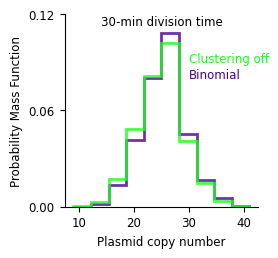

In [66]:
f = plt.figure(figsize=(2.5,2.5))
ax = f.add_subplot(111)
col = ["#1AFF1A","#4B0092"]
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz=8.5
ax.tick_params(axis='x', labelsize=fontsiz)
ax.tick_params(axis='y', labelsize=fontsiz)
combined_min = min(old_clustoff.min(), old_binom.min())
combined_max = max(old_clustoff.max(), old_binom.max())
num_bins = 10  # or choose based on rule like Freedman–Diaconis

# Create shared bin edges
bins = np.linspace(combined_min, combined_max, num_bins + 1)


ax.hist(old_binom,density=True,label='Bin. seg.',bins=bins,zorder=1000,fill=False,histtype='step',stacked=True,color=col[1],linewidth=2,alpha=0.8)
ax.hist(old_clustoff,density=True,label='Cluster off',bins=bins,zorder=1000,fill=False,histtype='step',stacked=True,color=col[0],linewidth=2,alpha=0.8)
ax.set_xlabel('Plasmid copy number',fontsize=fontsiz)
ax.set_ylabel('Probability Mass Function',fontsize=fontsiz)

ax.set_yticks([0,0.06,0.12])
ax.set_title('30-min division time',fontsize=fontsiz,y=0.9)
ax.text(30,0.09,'Clustering off',color=col[0],fontsize=fontsiz)
ax.text(30,0.08,'Binomial',color=col[1],fontsize=fontsiz)
sns.despine()
plt.savefig("cluster_off.pdf", format="pdf", bbox_inches="tight")

C:\Users\Jayson Cortez\AppData\Local\Temp\ipykernel_17292\3111045418.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  a=pd.concat([a1,a2,a3,a4,a5,a6,a7])


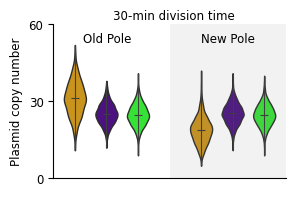

In [33]:
new_cluston = pd.read_csv("new_cluston.csv",header=None,skiprows=1).values
old_cluston = pd.read_csv("old_cluston.csv",header=None,skiprows=1).values

new_clustoff = pd.read_csv("new_clustoff.csv",header=None,skiprows=1).values
old_clustoff = pd.read_csv("old_clustoff.csv",header=None,skiprows=1).values

new_binom = pd.read_csv("new_binom.csv",header=None,skiprows=1).values
old_binom = pd.read_csv("old_binom.csv",header=None,skiprows=1).values

import matplotlib
col = ["#E69F00","#4B0092","#1AFF1A"]
fontsiz=8.5
tag1 = '1'
tag2 = '2'
tag3 = '3'
tag4 = '4'
tag5 = '5'
tag6 = '6'
tag7 = '7'
       
pal = {tag1: col[0], tag2: col[1], tag3: col[2], tag4: col[1], tag5: col[0],tag6: col[1],tag7: col[2]}

a1=pd.DataFrame(old_cluston,columns=[1]).assign(models=tag1)       
a2=pd.DataFrame(old_binom,columns=[1]).assign(models=tag2)
a3=pd.DataFrame(old_clustoff,columns=[1]).assign(models=tag3) 
a4=pd.DataFrame([ ],columns=[1]).assign(models=tag4)
a5=pd.DataFrame(new_cluston,columns=[1]).assign(models=tag5) 
a6=pd.DataFrame(new_binom,columns=[1]).assign(models=tag6)
a7=pd.DataFrame(new_clustoff,columns=[1]).assign(models=tag7) 


a=pd.concat([a1,a2,a3,a4,a5,a6,a7])
f,ax = plt.subplots(figsize=(3,2))
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

sns.violinplot(x='models',y=1,data=a,orient='v',palette=pal,order=[tag1,tag2,tag3,tag4,tag5,tag6,tag7],width=0.7,ax=ax,linewidth=1,cut=0,inner=None,scale='width')

order = [tag1, tag2, tag3, tag4, tag5, tag6, tag7]
for x, tag in enumerate(order):
    vals = a.loc[a['models'] == tag, 1].dropna()
    if len(vals) == 0:
        continue
    mean = vals.mean()
    ax.vlines(x, vals.min(), vals.max(), color='#3f3f3f', linewidth=0.8)
    ax.hlines(mean, x-0.12, x+0.12, color='#3f3f3f', linewidth=0.8)
    
#ax.set_xlim([-0.5,4.5])

ax.set_ylabel('Plasmid copy number',fontsize=fontsiz)
ax.set_xlabel(' ')
ax.set_yticks([0,30,60])
ax.set_yticklabels([0,30,60],fontsize=fontsiz)
ax.set_xticks([ ])
ax.set_xticklabels([ ])
ax.add_patch(Rectangle((3,0), 4, 72,
             facecolor = 'grey',
             fill=True,
             zorder=1,
             alpha=0.1))

ax.text(0.25,53,'Old Pole',color='k',fontsize=fontsiz)
ax.text(4,53,'New Pole',color='k',fontsize=fontsiz)
ax.text(1.2,62,'30-min division time',color='k',fontsize=fontsiz)


ax.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
sns.despine()
plt.savefig("cluster_compare.pdf", format="pdf", bbox_inches="tight")

In [35]:
summary = (
    a.groupby('models')[1]
     .agg(['mean', 'std'])
     .reindex([tag1, tag2, tag3, tag4, tag5, tag6, tag7])
)

print(summary)

             mean       std
models                     
1       31.155155  6.674733
2       25.242600  4.138402
3       24.817700  4.255570
4             NaN       NaN
5       18.937938  5.186130
6       25.328000  4.141527
7       24.740300  4.210253


In [36]:
from scipy.stats import ks_2samp

#### old pole comparison
statistic, pvalue = ks_2samp(
    old_binom.ravel(),
    old_clustoff.ravel(),
    alternative='two-sided',
    method='auto'
)

print(f"KS statistic = {statistic:.4f}")
print(f"p-value      = {pvalue:.4g}")

KS statistic = 0.0431
p-value      = 8.264e-06


In [37]:
#### new pole comparison
statistic, pvalue = ks_2samp(
    new_binom.ravel(),
    new_clustoff.ravel(),
    alternative='two-sided',
    method='auto'
)

print(f"KS statistic = {statistic:.4f}")
print(f"p-value      = {pvalue:.4g}")

KS statistic = 0.0629
p-value      = 6.807e-12


A two-sample Kolmogorov–Smirnov test indicated statistically significant differences between the plasmid copy number distributions at both the old and new poles. For the old pole, the test yielded a KS statistic of 0.0431 (p = 8.26 × 10⁻⁶), indicating a maximum discrepancy of approximately 4.3\% between the empirical cumulative distribution functions. For the new pole, the KS statistic was 0.0629 (p = 6.81 × 10⁻¹²), corresponding to a maximum discrepancy of approximately 6.3\%. Although both differences were statistically significant, the relatively small KS statistics suggest that the practical differences between the distributions were modest.

In [3]:
import numpy as np
from scipy.stats import wasserstein_distance

# Flatten arrays
x = old_binom.ravel()
y = old_clustoff.ravel()

W1 = wasserstein_distance(x, y)

print('old pole')
print(f"Wasserstein-1 distance = {W1:.4f}")

x = new_binom.ravel()
y = new_clustoff.ravel()
W1 = wasserstein_distance(x, y)

print('new pole')
print(f"Wasserstein-1 distance = {W1:.4f}")

old pole
Wasserstein-1 distance = 0.4307
new pole
Wasserstein-1 distance = 0.5895
